In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

pd.set_option({"display.max_columns": 200})
plt.style.use("ggplot")

In [2]:
df = pd.read_csv("data/train.csv")

In [3]:
df.shape

(8693, 14)

In [4]:
df

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,9276_01,Europa,False,A/98/P,55 Cancri e,41.0,True,0.0,6819.0,0.0,1643.0,74.0,Gravior Noxnuther,False
8689,9278_01,Earth,True,G/1499/S,PSO J318.5-22,18.0,False,0.0,0.0,0.0,0.0,0.0,Kurta Mondalley,False
8690,9279_01,Earth,False,G/1500/S,TRAPPIST-1e,26.0,False,0.0,0.0,1872.0,1.0,0.0,Fayey Connon,True
8691,9280_01,Europa,False,E/608/S,55 Cancri e,32.0,False,0.0,1049.0,0.0,353.0,3235.0,Celeon Hontichre,False


In [5]:
df.describe()

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck
count,8514.000000,8512.000000,8510.000000,8485.000000,8510.000000,8505.000000
mean,28.827930,224.687617,458.077203,173.729169,311.138778,304.854791
std,14.489021,666.717663,1611.489240,604.696458,1136.705535,1145.717189
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,19.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,38.000000,47.000000,76.000000,27.000000,59.000000,46.000000
max,79.000000,14327.000000,29813.000000,23492.000000,22408.000000,24133.000000


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8492 non-null   str    
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   str    
 4   Destination   8511 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   str    
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(2), str(5)
memory usage: 891.5+ KB


In [7]:
df.loc[df.duplicated()]

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported


In [8]:
cabin_splitted = df["Cabin"].str.split("/", expand=True)
df["Cabin_Deck"] = cabin_splitted[0]
df["Cabin_Num"] = cabin_splitted[1]
df["Cabin_Side"] = cabin_splitted[2]
df

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,Cabin_Deck,Cabin_Num,Cabin_Side
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False,B,0,P
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True,F,0,S
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False,A,0,S
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False,A,0,S
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True,F,1,S
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,9276_01,Europa,False,A/98/P,55 Cancri e,41.0,True,0.0,6819.0,0.0,1643.0,74.0,Gravior Noxnuther,False,A,98,P
8689,9278_01,Earth,True,G/1499/S,PSO J318.5-22,18.0,False,0.0,0.0,0.0,0.0,0.0,Kurta Mondalley,False,G,1499,S
8690,9279_01,Earth,False,G/1500/S,TRAPPIST-1e,26.0,False,0.0,0.0,1872.0,1.0,0.0,Fayey Connon,True,G,1500,S
8691,9280_01,Europa,False,E/608/S,55 Cancri e,32.0,False,0.0,1049.0,0.0,353.0,3235.0,Celeon Hontichre,False,E,608,S


In [9]:
df = df.drop(["PassengerId", "Cabin", "Name"], axis=1)
df

,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,Cabin_Deck,Cabin_Num,Cabin_Side
0,Europa,False,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,False,B,0,P
1,Earth,False,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,True,F,0,S
2,Europa,False,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,False,A,0,S
3,Europa,False,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,False,A,0,S
4,Earth,False,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,True,F,1,S
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,Europa,False,55 Cancri e,41.0,True,0.0,6819.0,0.0,1643.0,74.0,False,A,98,P
8689,Earth,True,PSO J318.5-22,18.0,False,0.0,0.0,0.0,0.0,0.0,False,G,1499,S
8690,Earth,False,TRAPPIST-1e,26.0,False,0.0,0.0,1872.0,1.0,0.0,True,G,1500,S
8691,Europa,False,55 Cancri e,32.0,False,0.0,1049.0,0.0,353.0,3235.0,False,E,608,S


In [10]:
df = df.rename(columns={
    "HomePlanet": "Home_Planet",
    "CryoSleep": "Cryo_Sleep",
    "RoomService": "Room_Service",
    "FoodCourt": "Food_Court",
    "ShoppingMall": "Shopping_Mall",
    "VRDeck": "VR_Deck",
})

In [11]:
df = df[["Home_Planet", "Destination", "Age", "Cryo_Sleep", "VIP", "Room_Service", "Food_Court", "Shopping_Mall", "Spa", "VR_Deck", "Cabin_Deck", "Cabin_Num", "Cabin_Side", "Transported"]]

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Home_Planet    8492 non-null   str    
 1   Destination    8511 non-null   str    
 2   Age            8514 non-null   float64
 3   Cryo_Sleep     8476 non-null   object 
 4   VIP            8490 non-null   object 
 5   Room_Service   8512 non-null   float64
 6   Food_Court     8510 non-null   float64
 7   Shopping_Mall  8485 non-null   float64
 8   Spa            8510 non-null   float64
 9   VR_Deck        8505 non-null   float64
 10  Cabin_Deck     8494 non-null   str    
 11  Cabin_Num      8494 non-null   str    
 12  Cabin_Side     8494 non-null   str    
 13  Transported    8693 non-null   bool   
dtypes: bool(1), float64(6), object(2), str(5)
memory usage: 891.5+ KB


In [13]:
df["Home_Planet"] = df["Home_Planet"].astype("category")
df["Destination"] = df["Destination"].astype("category")
df["Cryo_Sleep"] = df["Cryo_Sleep"].astype("bool")
df["VIP"] = df["VIP"].astype("bool")
df["Cabin_Deck"] = df["Cabin_Deck"].astype("category")
df["Cabin_Num"] = df["Cabin_Num"].astype("float")
df["Cabin_Side"] = df["Cabin_Side"].astype("category")

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype   
---  ------         --------------  -----   
 0   Home_Planet    8492 non-null   category
 1   Destination    8511 non-null   category
 2   Age            8514 non-null   float64 
 3   Cryo_Sleep     8693 non-null   bool    
 4   VIP            8693 non-null   bool    
 5   Room_Service   8512 non-null   float64 
 6   Food_Court     8510 non-null   float64 
 7   Shopping_Mall  8485 non-null   float64 
 8   Spa            8510 non-null   float64 
 9   VR_Deck        8505 non-null   float64 
 10  Cabin_Deck     8494 non-null   category
 11  Cabin_Num      8494 non-null   float64 
 12  Cabin_Side     8494 non-null   category
 13  Transported    8693 non-null   bool    
dtypes: bool(3), category(4), float64(7)
memory usage: 535.1 KB


In [15]:
df.isna().sum()

Home_Planet      201
Destination      182
Age              179
Cryo_Sleep         0
VIP                0
Room_Service     181
Food_Court       183
Shopping_Mall    208
Spa              183
VR_Deck          188
Cabin_Deck       199
Cabin_Num        199
Cabin_Side       199
Transported        0
dtype: int64

In [16]:
#df.loc[df.duplicated()]

In [17]:
#df = df.loc[~df.duplicated()].reset_index(drop=True)
#df.shape

In [18]:
df["Home_Planet"].value_counts()

Home_Planet
Earth     4602
Europa    2131
Mars      1759
Name: count, dtype: int64

Text(0, 0.5, 'Count')

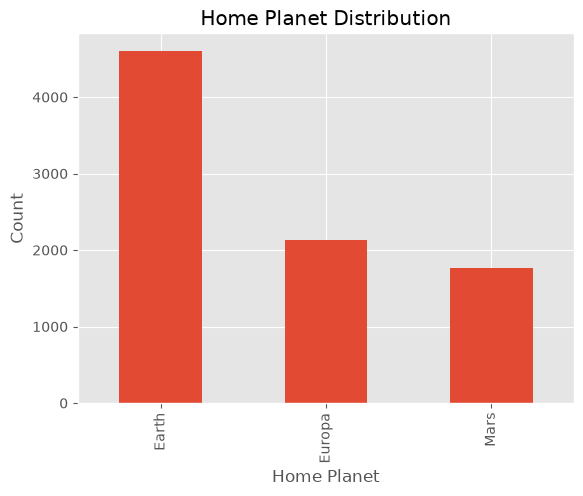

In [19]:
ax = df["Home_Planet"].value_counts().plot(kind="bar", title="Home Planet Distribution")
ax.set_xlabel("Home Planet")
ax.set_ylabel("Count")

Text(0, 0.5, 'Count')

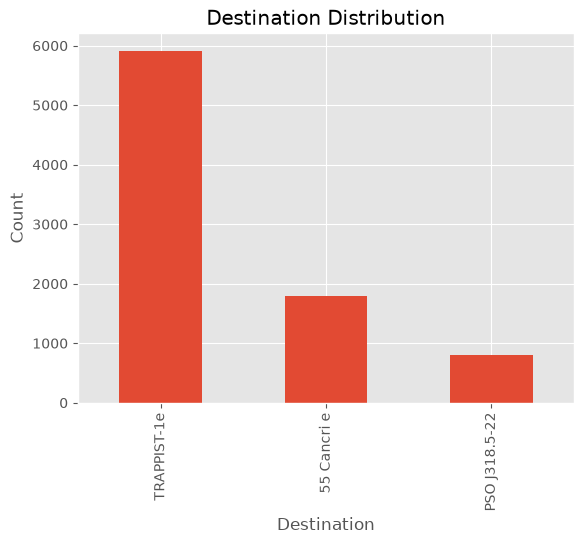

In [20]:
ax = df["Destination"].value_counts().plot(kind="bar", title="Destination Distribution")
ax.set_xlabel("Destination")
ax.set_ylabel("Count")

Text(0.5, 0, 'Age')

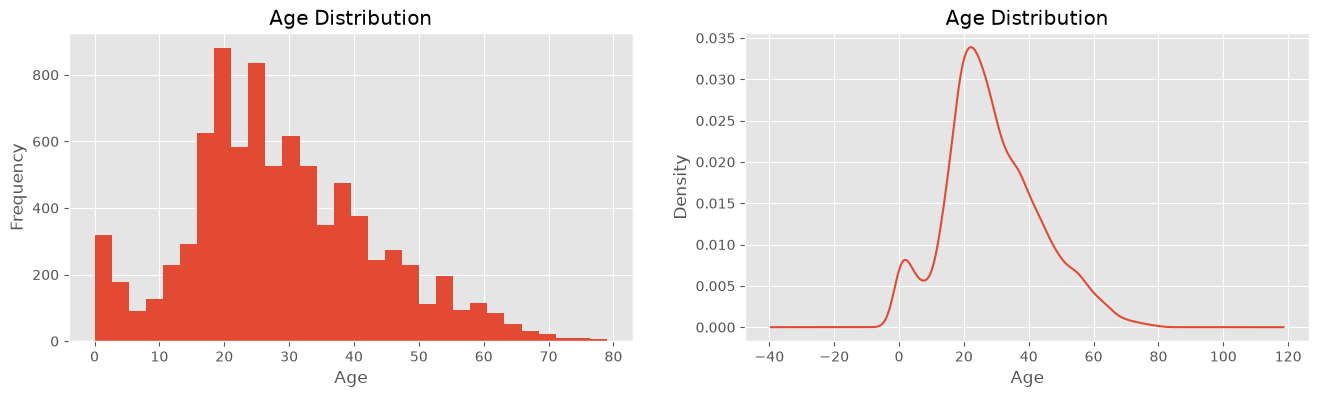

In [21]:
fig, axes = plt.subplots(ncols=2, figsize=(16,4))

ax = df["Age"].plot(kind="hist", ax=axes[0], title="Age Distribution", bins=30)
ax.set_xlabel("Age")
ax = df["Age"].plot(kind="kde", ax=axes[1], title="Age Distribution")
ax.set_xlabel("Age")

In [22]:
(df["Age"] == 0).sum()

np.int64(178)

In [23]:
df.query("Age == 0")

,Home_Planet,Destination,Age,Cryo_Sleep,VIP,Room_Service,Food_Court,Shopping_Mall,Spa,VR_Deck,Cabin_Deck,Cabin_Num,Cabin_Side,Transported
19,Earth,TRAPPIST-1e,0.0,False,False,0.0,0.0,0.0,0.0,0.0,G,0.0,P,True
61,Earth,PSO J318.5-22,0.0,True,False,0.0,0.0,0.0,0.0,0.0,G,10.0,S,True
86,Earth,TRAPPIST-1e,0.0,True,False,0.0,0.0,NaN,0.0,0.0,G,9.0,P,True
102,Earth,TRAPPIST-1e,0.0,False,True,0.0,0.0,0.0,0.0,0.0,G,19.0,S,True
157,Earth,TRAPPIST-1e,0.0,False,False,0.0,0.0,0.0,0.0,0.0,G,26.0,P,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8494,Earth,TRAPPIST-1e,0.0,True,True,0.0,0.0,NaN,0.0,0.0,G,1460.0,S,True
8584,Earth,TRAPPIST-1e,0.0,True,False,0.0,0.0,0.0,0.0,0.0,G,1477.0,S,True
8650,Earth,TRAPPIST-1e,0.0,True,False,0.0,0.0,0.0,0.0,0.0,G,1498.0,P,True
8654,Mars,TRAPPIST-1e,0.0,False,False,0.0,0.0,0.0,0.0,0.0,F,1888.0,P,True


Text(0.5, 0, 'Amount')

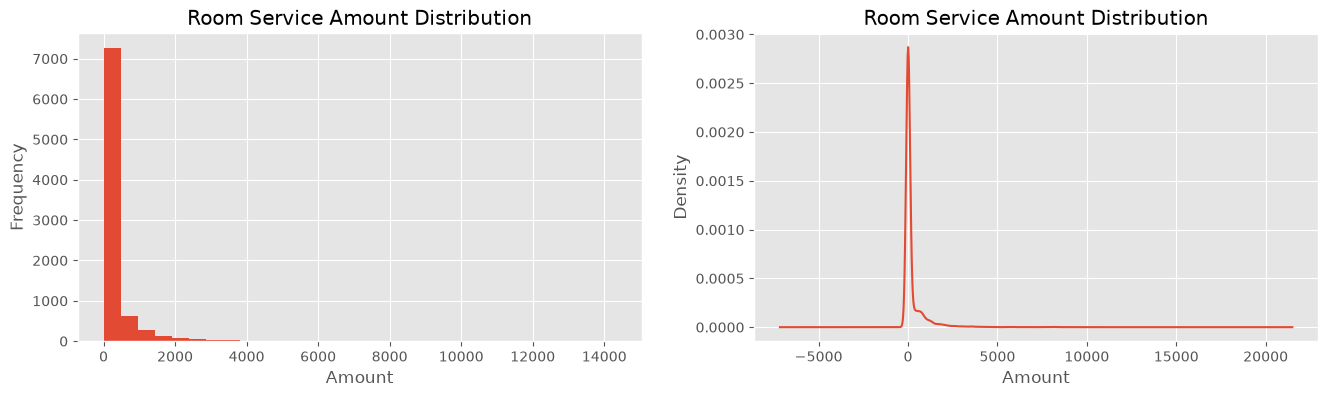

In [24]:
fig, axes = plt.subplots(ncols=2, figsize=(16,4))

ax = df["Room_Service"].plot(kind="hist", ax=axes[0], title="Room Service Amount Distribution", bins=30)
ax.set_xlabel("Amount")
ax = df["Room_Service"].plot(kind="kde", ax=axes[1], title="Room Service Amount Distribution")
ax.set_xlabel("Amount")

Text(0.5, 0, 'Amount')

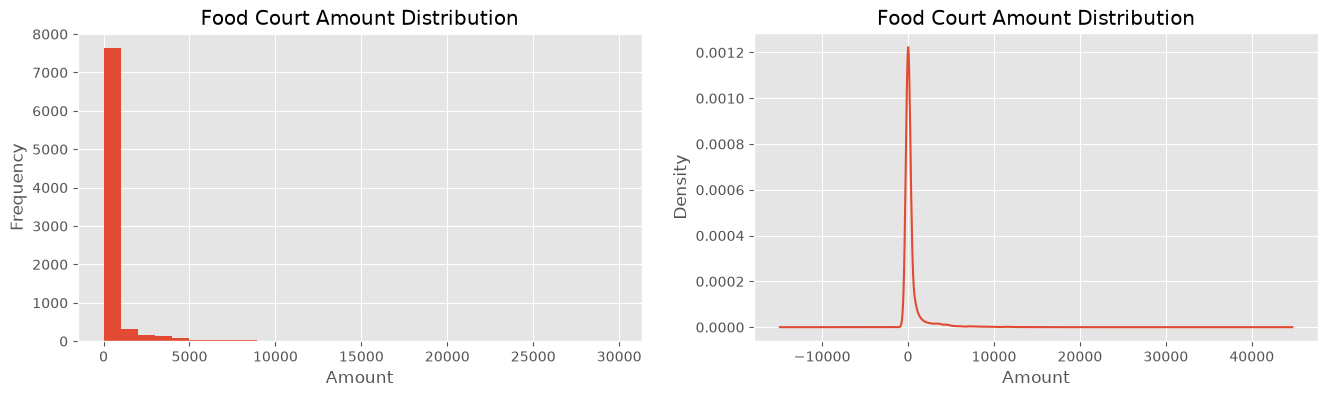

In [25]:
fig, axes = plt.subplots(ncols=2, figsize=(16,4))

ax = df["Food_Court"].plot(kind="hist", ax=axes[0], title="Food Court Amount Distribution", bins=30)
ax.set_xlabel("Amount")
ax = df["Food_Court"].plot(kind="kde", ax=axes[1], title="Food Court Amount Distribution")
ax.set_xlabel("Amount")

Text(0.5, 0, 'Amount')

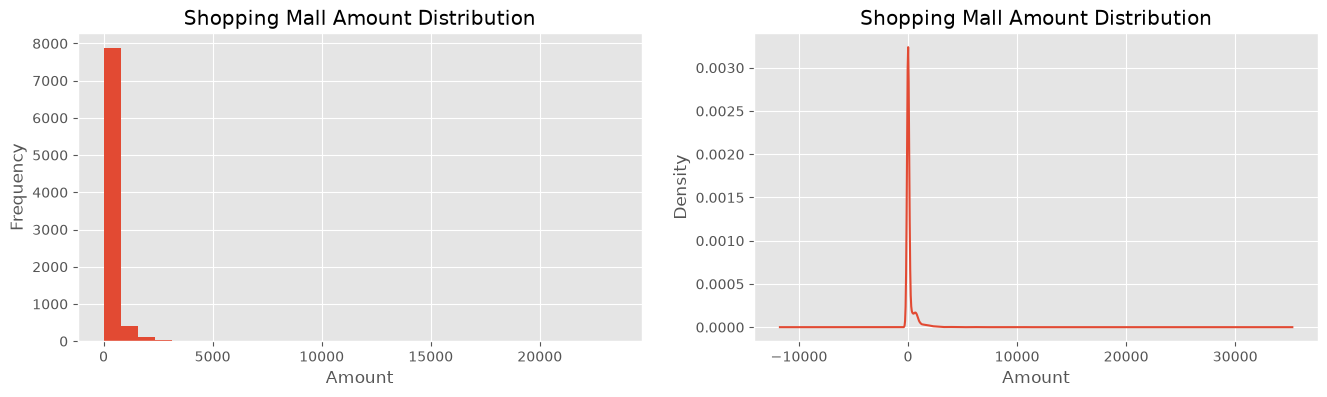

In [26]:
fig, axes = plt.subplots(ncols=2, figsize=(16,4))

ax = df["Shopping_Mall"].plot(kind="hist", ax=axes[0], title="Shopping Mall Amount Distribution", bins=30)
ax.set_xlabel("Amount")
ax = df["Shopping_Mall"].plot(kind="kde", ax=axes[1], title="Shopping Mall Amount Distribution")
ax.set_xlabel("Amount")

Text(0.5, 0, 'Amount')

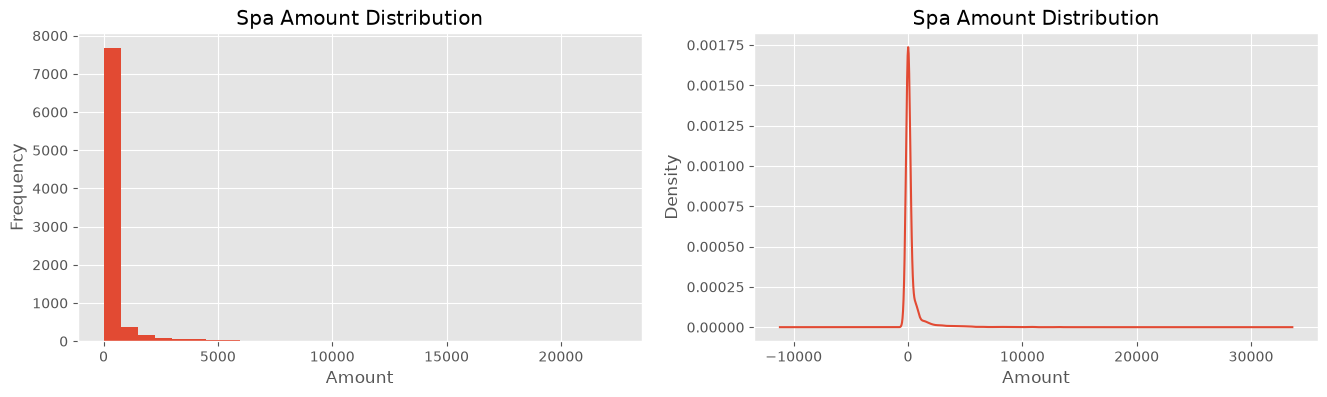

In [27]:
fig, axes = plt.subplots(ncols=2, figsize=(16,4))

ax = df["Spa"].plot(kind="hist", ax=axes[0], title="Spa Amount Distribution", bins=30)
ax.set_xlabel("Amount")
ax = df["Spa"].plot(kind="kde", ax=axes[1], title="Spa Amount Distribution")
ax.set_xlabel("Amount")

Text(0.5, 0, 'Amount')

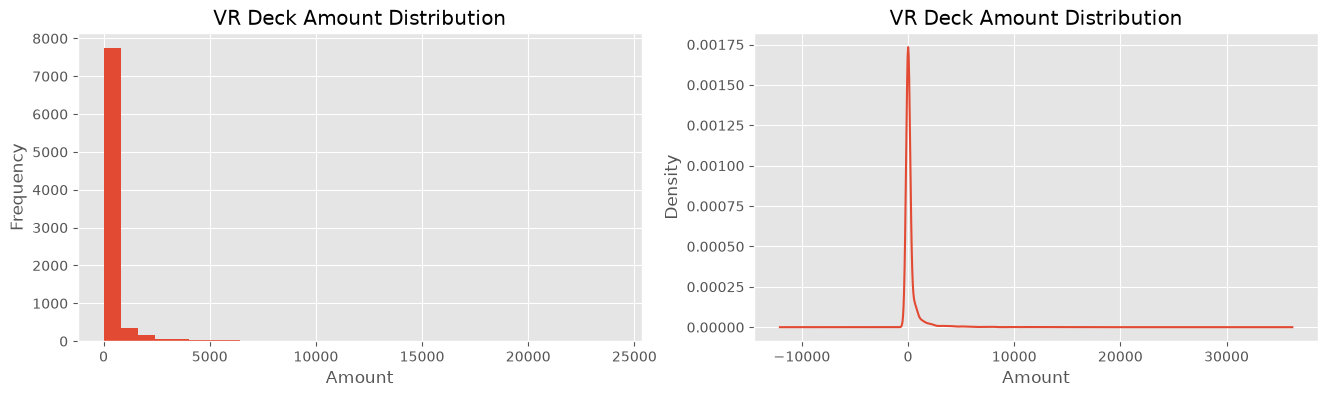

In [28]:
fig, axes = plt.subplots(ncols=2, figsize=(16,4))

ax = df["VR_Deck"].plot(kind="hist", ax=axes[0], title="VR Deck Amount Distribution", bins=30)
ax.set_xlabel("Amount")
ax = df["VR_Deck"].plot(kind="kde", ax=axes[1], title="VR Deck Amount Distribution")
ax.set_xlabel("Amount")

Text(0, 0.5, 'Count')

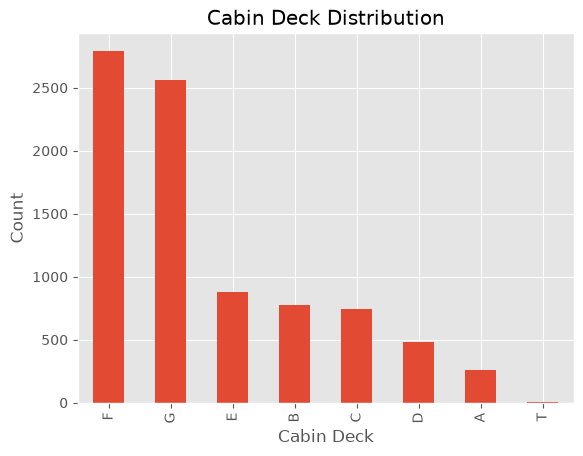

In [29]:
ax = df["Cabin_Deck"].value_counts().plot(kind="bar", title="Cabin Deck Distribution")
ax.set_xlabel("Cabin Deck")
ax.set_ylabel("Count")

Text(0.5, 0, 'Amount')

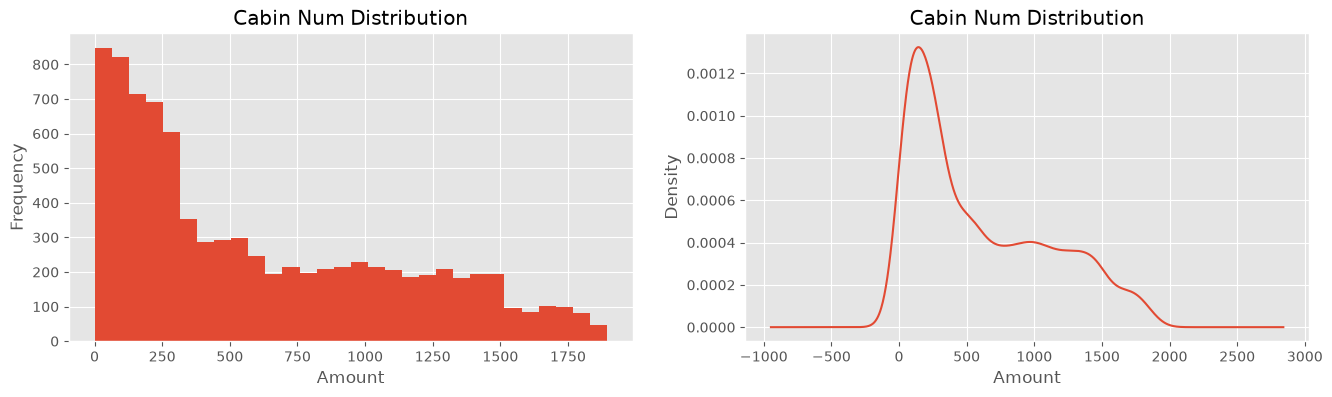

In [30]:
fig, axes = plt.subplots(ncols=2, figsize=(16,4))

ax = df["Cabin_Num"].plot(kind="hist", ax=axes[0], title="Cabin Num Distribution", bins=30)
ax.set_xlabel("Amount")
ax = df["Cabin_Num"].plot(kind="kde", ax=axes[1], title="Cabin Num Distribution")
ax.set_xlabel("Amount")

Text(0, 0.5, 'Count')

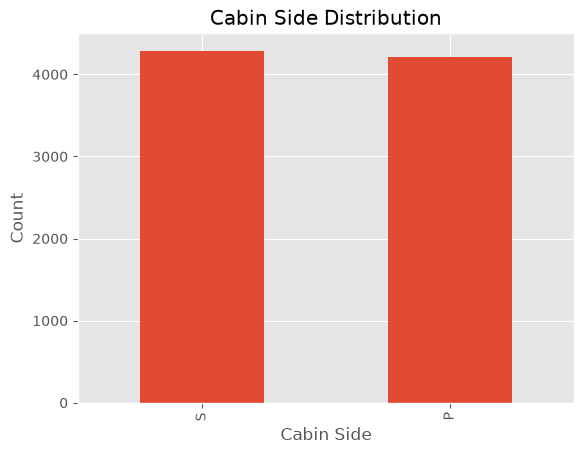

In [31]:
ax = df["Cabin_Side"].value_counts().plot(kind="bar", title="Cabin Side Distribution")
ax.set_xlabel("Cabin Side")
ax.set_ylabel("Count")

In [32]:
#sns.pairplot(df, vars=["Age", "Room_Service", "Food_Court", "Shopping_Mall", "Spa", "VR_Deck"], hue="Age")

In [33]:
#sns.heatmap(df[["Age", "Room_Service", "Food_Court", "Shopping_Mall", "Spa", "VR_Deck"]].dropna().corr(), annot=True)

In [34]:
# df["Total_Spent"] = df["Room_Service"] + df["Food_Court"] + df["Shopping_Mall"] + df["Spa"] + df["VR_Deck"]
# df["Total_Spent"] = np.log1p(df["Total_Spent"])
# df = df.drop(["Room_Service", "Food_Court", "Shopping_Mall", "Spa", "VR_Deck"], axis=1)

# df["Room_Service"] = np.log1p(df["Room_Service"])
# df["Food_Court"] = np.log1p(df["Food_Court"])
# df["Shopping_Mall"] = np.log1p(df["Shopping_Mall"])
# df["Spa"] = np.log1p(df["Spa"])
# df["VR_Deck"] = np.log1p(df["VR_Deck"])

In [35]:
# ax = df["Total_Spent"].plot(kind="hist", title="Log1p of Total Spent Distribution")
# ax.set_xlabel("log1p of Total Spent amount")

In [36]:
#sns.pairplot(df, vars=["Age", "Room_Service", "Food_Court", "Shopping_Mall", "Spa", "VR_Deck"], hue="Age")

In [37]:
df.isna().sum()

Home_Planet      201
Destination      182
Age              179
Cryo_Sleep         0
VIP                0
Room_Service     181
Food_Court       183
Shopping_Mall    208
Spa              183
VR_Deck          188
Cabin_Deck       199
Cabin_Num        199
Cabin_Side       199
Transported        0
dtype: int64

In [38]:
age_mean = df["Age"].fillna(df["Age"].mean())
room_service_median = df["Room_Service"].median()
food_court_median = df["Food_Court"].median()
shopping_mall_median = df["Shopping_Mall"].median()
spa_median = df["Spa"].median()
vr_deck_median = df["VR_Deck"].median()
# total_spent_median = df["Total_Spent"].median()
cabin_num_median = df["Cabin_Num"].median().astype("int8")

df["Age"] = age_mean

df["Room_Service"] = df["Room_Service"].fillna(room_service_median)
df["Food_Court"] = df["Food_Court"].fillna(food_court_median)
df["Shopping_Mall"] = df["Shopping_Mall"].fillna(shopping_mall_median)
df["Spa"] = df["Spa"].fillna(spa_median)
df["VR_Deck"] = df["VR_Deck"].fillna(vr_deck_median)
# df["Total_Spent"] = df["Total_Spent"].fillna(cabin_num_median)
df["Cabin_Num"] = df["Cabin_Num"].fillna(cabin_num_median)

In [39]:
home_planet_moda = df["Home_Planet"].value_counts().index[0]
destination_moda = df["Destination"].value_counts().index[0]
cabin_deck_moda = df["Cabin_Deck"].value_counts().index[0]
cabin_side_moda = df["Cabin_Side"].value_counts().index[0]

df["Home_Planet"] = df["Home_Planet"].fillna(home_planet_moda)
df["Destination"] = df["Destination"].fillna(destination_moda)
df["Cabin_Deck"] = df["Cabin_Deck"].fillna(cabin_deck_moda)
df["Cabin_Side"] = df["Cabin_Side"].fillna(cabin_side_moda)

In [40]:
df.isna().sum()

Home_Planet      0
Destination      0
Age              0
Cryo_Sleep       0
VIP              0
Room_Service     0
Food_Court       0
Shopping_Mall    0
Spa              0
VR_Deck          0
Cabin_Deck       0
Cabin_Num        0
Cabin_Side       0
Transported      0
dtype: int64

In [41]:
df

,Home_Planet,Destination,Age,Cryo_Sleep,VIP,Room_Service,Food_Court,Shopping_Mall,Spa,VR_Deck,Cabin_Deck,Cabin_Num,Cabin_Side,Transported
0,Europa,TRAPPIST-1e,39.0,False,False,0.0,0.0,0.0,0.0,0.0,B,0.0,P,False
1,Earth,TRAPPIST-1e,24.0,False,False,109.0,9.0,25.0,549.0,44.0,F,0.0,S,True
2,Europa,TRAPPIST-1e,58.0,False,True,43.0,3576.0,0.0,6715.0,49.0,A,0.0,S,False
3,Europa,TRAPPIST-1e,33.0,False,False,0.0,1283.0,371.0,3329.0,193.0,A,0.0,S,False
4,Earth,TRAPPIST-1e,16.0,False,False,303.0,70.0,151.0,565.0,2.0,F,1.0,S,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,Europa,55 Cancri e,41.0,False,True,0.0,6819.0,0.0,1643.0,74.0,A,98.0,P,False
8689,Earth,PSO J318.5-22,18.0,True,False,0.0,0.0,0.0,0.0,0.0,G,1499.0,S,False
8690,Earth,TRAPPIST-1e,26.0,False,False,0.0,0.0,1872.0,1.0,0.0,G,1500.0,S,True
8691,Europa,55 Cancri e,32.0,False,False,0.0,1049.0,0.0,353.0,3235.0,E,608.0,S,False


In [42]:
df = pd.concat([df, pd.get_dummies(df["Cabin_Deck"], prefix="Cabin_Deck")], axis=1)
df = df.drop(["Cabin_Deck"], axis=1)

In [43]:
df["Home_Planet"] = df["Home_Planet"].cat.codes
df["Destination"] = df["Destination"].cat.codes
#df["Cabin_Deck"] = df["Cabin_Deck"].cat.codes
df["Cabin_Side"] = df["Cabin_Side"].cat.codes

df = df.replace({True: 1, False: 0})
df

,Home_Planet,Destination,Age,Cryo_Sleep,VIP,Room_Service,Food_Court,Shopping_Mall,Spa,VR_Deck,Cabin_Num,Cabin_Side,Transported,Cabin_Deck_A,Cabin_Deck_B,Cabin_Deck_C,Cabin_Deck_D,Cabin_Deck_E,Cabin_Deck_F,Cabin_Deck_G,Cabin_Deck_T
0,1,2,39.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1,0,0,0,0,0,0
1,0,2,24.0,0,0,109.0,9.0,25.0,549.0,44.0,0.0,1,1,0,0,0,0,0,1,0,0
2,1,2,58.0,0,1,43.0,3576.0,0.0,6715.0,49.0,0.0,1,0,1,0,0,0,0,0,0,0
3,1,2,33.0,0,0,0.0,1283.0,371.0,3329.0,193.0,0.0,1,0,1,0,0,0,0,0,0,0
4,0,2,16.0,0,0,303.0,70.0,151.0,565.0,2.0,1.0,1,1,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,1,0,41.0,0,1,0.0,6819.0,0.0,1643.0,74.0,98.0,0,0,1,0,0,0,0,0,0,0
8689,0,1,18.0,1,0,0.0,0.0,0.0,0.0,0.0,1499.0,1,0,0,0,0,0,0,0,1,0
8690,0,2,26.0,0,0,0.0,0.0,1872.0,1.0,0.0,1500.0,1,1,0,0,0,0,0,0,1,0
8691,1,0,32.0,0,0,0.0,1049.0,0.0,353.0,3235.0,608.0,1,0,0,0,0,0,1,0,0,0


In [44]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Home_Planet    8693 non-null   int8   
 1   Destination    8693 non-null   int8   
 2   Age            8693 non-null   float64
 3   Cryo_Sleep     8693 non-null   object 
 4   VIP            8693 non-null   object 
 5   Room_Service   8693 non-null   float64
 6   Food_Court     8693 non-null   float64
 7   Shopping_Mall  8693 non-null   float64
 8   Spa            8693 non-null   float64
 9   VR_Deck        8693 non-null   float64
 10  Cabin_Num      8693 non-null   float64
 11  Cabin_Side     8693 non-null   int8   
 12  Transported    8693 non-null   object 
 13  Cabin_Deck_A   8693 non-null   object 
 14  Cabin_Deck_B   8693 non-null   object 
 15  Cabin_Deck_C   8693 non-null   object 
 16  Cabin_Deck_D   8693 non-null   object 
 17  Cabin_Deck_E   8693 non-null   object 
 18  Cabin_Deck_F   8693

In [45]:
df["Cryo_Sleep"] = df["Cryo_Sleep"].astype("int8")
df["VIP"] = df["VIP"].astype("int8")
df["Transported"] = df["Transported"].astype("int8")
df["Cabin_Deck_A"] = df["Cabin_Deck_A"].astype("int8")
df["Cabin_Deck_B"] = df["Cabin_Deck_B"].astype("int8")
df["Cabin_Deck_C"] = df["Cabin_Deck_C"].astype("int8")
df["Cabin_Deck_D"] = df["Cabin_Deck_D"].astype("int8")
df["Cabin_Deck_E"] = df["Cabin_Deck_E"].astype("int8")
df["Cabin_Deck_F"] = df["Cabin_Deck_F"].astype("int8")
df["Cabin_Deck_G"] = df["Cabin_Deck_G"].astype("int8")
df["Cabin_Deck_T"] = df["Cabin_Deck_T"].astype("int8")

In [46]:
y = df["Transported"]
X = df.drop(columns=["Transported"])

In [47]:
cols_to_scale = ["Age", "Room_Service", "Food_Court", "Shopping_Mall", "Spa", "VR_Deck", "Cabin_Num"]
# cols_to_scale = ["Age", "Total_Spent", "Cabin_Num"]

scaler = StandardScaler().fit(X[cols_to_scale])
X_scaled = X.copy()
X_scaled[cols_to_scale] = pd.DataFrame(scaler.transform(X[cols_to_scale]))
X_scaled

,Home_Planet,Destination,Age,Cryo_Sleep,VIP,Room_Service,Food_Court,Shopping_Mall,Spa,VR_Deck,Cabin_Num,Cabin_Side,Cabin_Deck_A,Cabin_Deck_B,Cabin_Deck_C,Cabin_Deck_D,Cabin_Deck_E,Cabin_Deck_F,Cabin_Deck_G,Cabin_Deck_T
0,1,2,0.709437,0,0,-0.333105,-0.281027,-0.283579,-0.270626,-0.263003,-1.132606,0,0,1,0,0,0,0,0,0
1,0,2,-0.336717,0,0,-0.168073,-0.275387,-0.241771,0.217158,-0.224205,-1.132606,1,0,0,0,0,0,1,0,0
2,1,2,2.034566,0,1,-0.268001,1.959998,-0.283579,5.695623,-0.219796,-1.132606,1,1,0,0,0,0,0,0,0
3,1,2,0.290975,0,0,-0.333105,0.523010,0.336851,2.687176,-0.092818,-1.132606,1,1,0,0,0,0,0,0,0
4,0,2,-0.894666,0,0,0.125652,-0.237159,-0.031059,0.231374,-0.261240,-1.130669,1,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,1,0,0.848924,0,1,-0.333105,3.992336,-0.283579,1.189173,-0.197751,-0.942766,0,1,0,0,0,0,0,0,0
8689,0,1,-0.755179,1,0,-0.333105,-0.281027,-0.283579,-0.270626,-0.263003,1.771174,1,0,0,0,0,0,0,1,0
8690,0,2,-0.197230,0,0,-0.333105,-0.281027,2.846999,-0.269737,-0.263003,1.773111,1,0,0,0,0,0,0,1,0
8691,1,0,0.221232,0,0,-0.333105,0.376365,-0.283579,0.043013,2.589576,0.045178,1,0,0,0,0,1,0,0,0


In [48]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_scaled, y)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [49]:
def preprocess_df(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    df_pid = df["PassengerId"]
    
    cabin_splitted = df["Cabin"].str.split("/", expand=True)
    df["Cabin_Deck"] = cabin_splitted[0]
    df["Cabin_Num"] = cabin_splitted[1]
    df["Cabin_Side"] = cabin_splitted[2]
    
    df = df.drop(["PassengerId", "Cabin", "Name"], axis=1)
    
    df = df.rename(columns={
        "HomePlanet": "Home_Planet",
        "CryoSleep": "Cryo_Sleep",
        "RoomService": "Room_Service",
        "FoodCourt": "Food_Court",
        "ShoppingMall": "Shopping_Mall",
        "VRDeck": "VR_Deck",
    })
    
    df = df[["Home_Planet", "Destination", "Age", "Cryo_Sleep", "VIP", "Room_Service", "Food_Court", "Shopping_Mall", "Spa", "VR_Deck", "Cabin_Deck", "Cabin_Num", "Cabin_Side"]]
    
    df["Home_Planet"] = df["Home_Planet"].astype("category")
    df["Destination"] = df["Destination"].astype("category")
    df["Cryo_Sleep"] = df["Cryo_Sleep"].astype("bool")
    df["VIP"] = df["VIP"].astype("bool")
    df["Cabin_Deck"] = df["Cabin_Deck"].astype("category")
    df["Cabin_Num"] = df["Cabin_Num"].astype("float")
    df["Cabin_Side"] = df["Cabin_Side"].astype("category")

    # df["Total_Spent"] = df["Room_Service"] + df["Food_Court"] + df["Shopping_Mall"] + df["Spa"] + df["VR_Deck"]
    # df["Total_Spent"] = np.log1p(df["Total_Spent"])
    # df = df.drop(["Room_Service", "Food_Court", "Shopping_Mall", "Spa", "VR_Deck"], axis=1)

    # df["Room_Service"] = np.log1p(df["Room_Service"])
    # df["Food_Court"] = np.log1p(df["Food_Court"])
    # df["Shopping_Mall"] = np.log1p(df["Shopping_Mall"])
    # df["Spa"] = np.log1p(df["Spa"])
    # df["VR_Deck"] = np.log1p(df["VR_Deck"])
    
    df["Age"] = age_mean

    df["Room_Service"] = df["Room_Service"].fillna(room_service_median)
    df["Food_Court"] = df["Food_Court"].fillna(food_court_median)
    df["Shopping_Mall"] = df["Shopping_Mall"].fillna(shopping_mall_median)
    df["Spa"] = df["Spa"].fillna(spa_median)
    df["VR_Deck"] = df["VR_Deck"].fillna(vr_deck_median)
    # df["Total_Spent"] = df["Total_Spent"].fillna(total_spent_median)
    df["Cabin_Num"] = df["Cabin_Num"].fillna(cabin_num_median)
    
    df["Home_Planet"] = df["Home_Planet"].fillna(home_planet_moda)
    df["Destination"] = df["Destination"].fillna(destination_moda)
    df["Cabin_Deck"] = df["Cabin_Deck"].fillna(cabin_deck_moda)
    df["Cabin_Side"] = df["Cabin_Side"].fillna(cabin_side_moda)
    
    df = pd.concat([df, pd.get_dummies(df["Cabin_Deck"], prefix="Cabin_Deck")], axis=1)
    df = df.drop(["Cabin_Deck"], axis=1)
    
    df["Home_Planet"] = df["Home_Planet"].cat.codes
    df["Destination"] = df["Destination"].cat.codes
    #df["Cabin_Deck"] = df["Cabin_Deck"].cat.codes
    df["Cabin_Side"] = df["Cabin_Side"].cat.codes
    
    df = df.replace({True: 1, False: 0})
    
    df["Cryo_Sleep"] = df["Cryo_Sleep"].astype("int8")
    df["VIP"] = df["VIP"].astype("int8")
    df["Cabin_Deck_A"] = df["Cabin_Deck_A"].astype("int8")
    df["Cabin_Deck_B"] = df["Cabin_Deck_B"].astype("int8")
    df["Cabin_Deck_C"] = df["Cabin_Deck_C"].astype("int8")
    df["Cabin_Deck_D"] = df["Cabin_Deck_D"].astype("int8")
    df["Cabin_Deck_E"] = df["Cabin_Deck_E"].astype("int8")
    df["Cabin_Deck_F"] = df["Cabin_Deck_F"].astype("int8")
    df["Cabin_Deck_G"] = df["Cabin_Deck_G"].astype("int8")
    df["Cabin_Deck_T"] = df["Cabin_Deck_T"].astype("int8")
    
    cols_to_scale = ["Age", "Room_Service", "Food_Court", "Shopping_Mall", "Spa", "VR_Deck", "Cabin_Num"]
    # cols_to_scale = ["Age", "Total_Spent", "Cabin_Num"]

    df_scaled = df.copy()
    df_scaled[cols_to_scale] = pd.DataFrame(scaler.transform(df[cols_to_scale]))
    df_scaled

    return df_scaled, df_pid

test_df = pd.read_csv("data/test.csv")

test_df_scaled, test_df_pid = preprocess_df(test_df)

In [50]:
test_df_scaled

,Home_Planet,Destination,Age,Cryo_Sleep,VIP,Room_Service,Food_Court,Shopping_Mall,Spa,VR_Deck,Cabin_Num,Cabin_Side,Cabin_Deck_A,Cabin_Deck_B,Cabin_Deck_C,Cabin_Deck_D,Cabin_Deck_E,Cabin_Deck_F,Cabin_Deck_G,Cabin_Deck_T
0,0,2,0.709437,1,0,-0.333105,-0.281027,-0.283579,-0.270626,-0.263003,-1.126795,1,0,0,0,0,0,0,1,0
1,0,2,-0.336717,0,0,-0.333105,-0.275387,-0.283579,2.237598,-0.263003,-1.124858,1,0,0,0,0,0,1,0,0
2,1,0,2.034566,1,0,-0.333105,-0.281027,-0.283579,-0.270626,-0.263003,-1.132606,1,0,0,1,0,0,0,0,0
3,1,2,0.290975,0,0,-0.333105,3.887680,-0.283579,-0.109808,0.252842,-1.130669,1,0,0,1,0,0,0,0,0
4,0,2,-0.894666,0,0,-0.317964,-0.281027,0.778343,-0.270626,-0.263003,-1.122921,1,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4272,0,2,0.918668,1,0,-0.333105,-0.281027,-0.283579,-0.270626,-0.263003,1.765362,1,0,0,0,0,0,0,1,0
4273,0,2,-0.057743,0,0,-0.333105,0.249775,-0.255149,-0.261741,-0.136026,-1.297264,1,0,0,0,0,0,1,0,0
4274,2,0,0.988411,1,0,-0.333105,-0.281027,-0.283579,-0.270626,-0.263003,-0.559212,0,0,0,0,1,0,0,0,0
4275,1,2,1.825335,0,0,-0.333105,1.398488,-0.283579,-0.270626,0.198171,-0.557274,0,0,0,0,1,0,0,0,0


In [51]:
predictions = model.predict(test_df_scaled)

In [52]:
submission_df = pd.DataFrame({"PassengerId": test_df_pid, "Transported": pd.Series(predictions).astype(bool)})
submission_df

,PassengerId,Transported
0,0013_01,True
1,0018_01,False
2,0019_01,True
3,0021_01,True
4,0023_01,True
...,...,...
4272,9266_02,True
4273,9269_01,True
4274,9271_01,True
4275,9273_01,True


In [53]:
submission_df.to_csv("submission.csv", index=False)